# Large-scale bundle adjustment with piazzi and SE(3) cameras

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cai4cai/torch-piazzi/blob/main/notebooks/bundle_adjustment.ipynb)

This notebook follows the SciPy Cookbook example [Large-scale bundle adjustment in scipy](https://scipy-cookbook.readthedocs.io/items/bundle_adjustment.html) (Nikolay Mayorov, BSD licence), with `piazzi` and PyTorch in place of `scipy.optimize.least_squares`.

Bundle adjustment refines camera parameters and 3D points together, so that the points reprojected into the cameras match the observed 2D features. It is a nonlinear least-squares problem with tens of thousands of parameters, but each residual depends on one camera and one point only, so its Jacobian is very sparse.

Compared with the cookbook, this version:

- stores each camera pose as a 4 x 4 rigid transform and optimises it on SE(3) with `piazzi.SE3`, instead of as a rotation vector plus translation;
- gets the Jacobian from PyTorch autodiff through the manifold's `plus`, instead of finite differences with a sparsity pattern;
- builds the sparse normal equations `J^T J` explicitly and solves them in two ways: with preconditioned conjugate gradients from [torchsparsegradutils](https://github.com/cai4cai/torchsparsegradutils) (generic), and with the Schur complement (which exploits the camera/point structure, as bundle-adjustment solvers such as Ceres do).

## Setup

On Colab, the next cell installs `piazzi` from GitHub, with the optional `sparse` dependencies (torchsparsegradutils). Locally, install the notebook dependencies with `uv sync --group notebooks` (see the README).

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "piazzi[sparse] @ git+https://github.com/cai4cai/torch-piazzi"

In [2]:
import bz2
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

import piazzi

torch.set_default_dtype(torch.float64)
# torch 2.15 and earlier warn spuriously the first time forward-mode autodiff runs
# (fixed upstream in https://github.com/pytorch/pytorch/pull/203621).
warnings.filterwarnings("ignore", r"`torch\.jit\.script` is deprecated", FutureWarning)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["legend.fontsize"] = 12
plt.rcParams["axes.labelsize"] = 14

## The data

As in the cookbook, we use the "Ladybug" problem with 49 cameras from the [Bundle Adjustment in the Large](https://grail.cs.washington.edu/projects/bal/) (BAL) dataset. Each camera has 9 parameters: a rotation vector $\mathbf{r}$, a translation $\mathbf{t}$, a focal length $f$ and two radial distortion coefficients $k_1, k_2$. A world point $\mathbf{X}$ projects to

$$
\mathbf{P} = R(\mathbf{r})\,\mathbf{X} + \mathbf{t}, \qquad
\mathbf{p} = -\mathbf{P}_{xy} / P_z, \qquad
\mathbf{u} = f\,(1 + k_1 \|\mathbf{p}\|^2 + k_2 \|\mathbf{p}\|^4)\,\mathbf{p}.
$$

The file is downloaded once (about 450 KB) and cached next to the notebook.

In [3]:
URL = "https://grail.cs.washington.edu/projects/bal/data/ladybug/problem-49-7776-pre.txt.bz2"
path = Path(URL.rsplit("/", 1)[1])
if not path.exists():
    urllib.request.urlretrieve(URL, path)


def read_bal_data(path):
    with bz2.open(path, "rt") as f:
        n_cameras, n_points, n_observations = map(int, f.readline().split())
        observations = np.loadtxt(f, max_rows=n_observations)
        params = np.loadtxt(f)
    camera_params = params[: n_cameras * 9].reshape(n_cameras, 9)
    points_3d = params[n_cameras * 9 :].reshape(n_points, 3)
    camera_indices = observations[:, 0].astype(int)
    point_indices = observations[:, 1].astype(int)
    points_2d = observations[:, 2:]
    return camera_params, points_3d, camera_indices, point_indices, points_2d


camera_params, points_3d, camera_indices, point_indices, points_2d = read_bal_data(path)
n_cameras, n_points, n_observations = len(camera_params), len(points_3d), len(points_2d)
print(f"cameras: {n_cameras}, points: {n_points}, observations: {n_observations}")
print(f"parameters (as in the cookbook): {9 * n_cameras + 3 * n_points}, residuals: {2 * n_observations}")

cameras: 49, points: 7776, observations: 31843
parameters (as in the cookbook): 23769, residuals: 63686


## Cameras on SE(3)

Each BAL camera maps world coordinates to camera coordinates, $\mathbf{P} = R\mathbf{X} + \mathbf{t}$. We store this map as a 4 x 4 rigid transform $T = \begin{bmatrix} R & \mathbf{t} \\ 0 & 1 \end{bmatrix}$ and let `piazzi.SE3` keep it rigid during the optimisation, with 6 degrees of freedom per pose.

`piazzi.SE3(side="left")` updates a pose as $T \leftarrow \Delta(\boldsymbol\delta)\,T$: the increment $\Delta$ acts in the camera frame, so its rotation turns about the camera centre. With the default `side="right"` it would act in the world frame and rotate about the world origin, which for a camera far from the origin couples rotation with a large translation and slows convergence. (For a pose stored camera-to-world, `side="right"` would be the natural choice.)

The whole parameter vector is a `piazzi.Product`: for each camera a pose (`SE3`, 16 stored numbers, 6 degrees of freedom) and its intrinsics $(f, k_1, k_2)$ (`Euclidean(3)`), then all the points (`Euclidean`). That is $49 \times 9 + 7776 \times 3 = 23\,769$ degrees of freedom, as in the cookbook, stored in $49 \times 19 + 7776 \times 3 = 24\,259$ numbers.

In [4]:
pose = piazzi.SE3(side="left")
manifold = piazzi.Product(
    *[m for _ in range(n_cameras) for m in (pose, piazzi.Euclidean(3))], piazzi.Euclidean(3 * n_points)
)

T0 = torch.eye(4).repeat(n_cameras, 1, 1)
T0[:, :3, :3] = piazzi.so3_exp(torch.as_tensor(camera_params[:, :3]))
T0[:, :3, 3] = torch.as_tensor(camera_params[:, 3:6])
intrinsics0 = torch.as_tensor(camera_params[:, 6:])
x0 = torch.cat(
    [torch.cat([T0.reshape(n_cameras, 16), intrinsics0], 1).reshape(-1), torch.as_tensor(points_3d).reshape(-1)]
)

cam_idx = torch.as_tensor(camera_indices)
pt_idx = torch.as_tensor(point_indices)
uv = torch.as_tensor(points_2d)
n_cam_dof = 9 * n_cameras  # tangent coordinates: 9 per camera (6 pose + 3 intrinsics), then 3 per point


def unpack(x):
    # Same layout as manifold.split(x), but batched: (poses, intrinsics, points).
    cams = x[: 19 * n_cameras].reshape(n_cameras, 19)
    return cams[:, :16].reshape(n_cameras, 4, 4), cams[:, 16:], x[19 * n_cameras :].reshape(n_points, 3)


print("ambient size:", manifold.ambient_size, " tangent size:", manifold.tangent_size(x0))

ambient size: 24259  tangent size: 23769


## Residuals

`project` maps one point through one camera; `torch.vmap` applies it to all observations.

initial cost: 850912


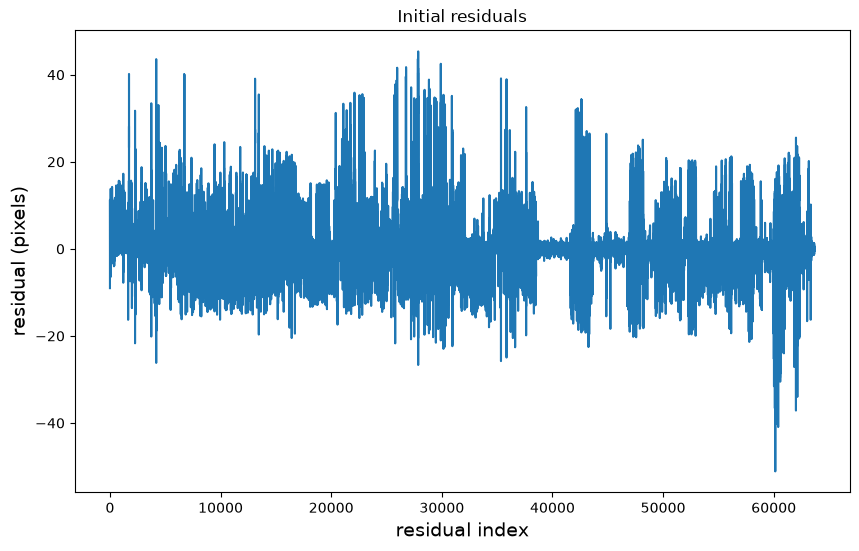

In [5]:
def project(T, k, X):
    P = T[:3, :3] @ X + T[:3, 3]
    p = -P[:2] / P[2]
    n = (p * p).sum()
    return k[0] * (1 + k[1] * n + k[2] * n * n) * p


def residuals(x):
    T, k, X = unpack(x)
    return torch.vmap(project)(T[cam_idx], k[cam_idx], X[pt_idx]) - uv


def cost(x):
    r = residuals(x)
    return 0.5 * (r * r).sum()


r0 = residuals(x0)
print(f"initial cost: {cost(x0).item():.6g}")
plt.plot(r0.reshape(-1))
plt.xlabel("residual index")
plt.ylabel("residual (pixels)")
plt.title("Initial residuals");

## Sparse normal equations on the manifold

`piazzi.least_squares` builds a dense Jacobian, which is out of the question here ($63\,686 \times 23\,769$). Instead we write the `system(x) -> (loss, g, H)` that `piazzi.gauss_newton` expects, with a sparse `H`.

Residual $i$ depends only on camera $c_i$ and point $p_i$. Following the manifold recipe, its Jacobian is that of

$$
\boldsymbol\delta \mapsto \text{project}\big(\text{plus}(T_{c_i}, \boldsymbol\delta_T),\; \mathbf{k}_{c_i} + \boldsymbol\delta_k,\; \mathbf{X}_{p_i} + \boldsymbol\delta_X\big) - \mathbf{u}_i
$$

at $\boldsymbol\delta = 0$: a $2 \times 12$ block, computed for all observations at once with `torch.func.jacfwd` inside `torch.vmap`, through `pose.plus`. The normal equations have the classic bundle-adjustment structure

$$
H = J^\top J = \begin{bmatrix} U & W \\ W^\top & V \end{bmatrix},
$$

with $9 \times 9$ camera blocks $U$ and $3 \times 3$ point blocks $V$ on the diagonal, and a $9 \times 3$ block of $W$ for every observation. We assemble it as a sparse COO tensor.

In [6]:
def observation_residual(T, k, X, u, d_pose, d_k, d_X):
    return project(pose.plus(T, d_pose), k + d_k, X + d_X) - u


observation_jacobian = torch.vmap(
    torch.func.jacfwd(observation_residual, argnums=(4, 5, 6)), in_dims=(0, 0, 0, 0, None, None, None)
)
zeros6, zeros3 = torch.zeros(6), torch.zeros(3)


def block_indices(starts, rows, cols):
    # Row and column indices of dense blocks of shape (rows, cols) whose top-left corners are `starts`.
    r = starts[0][:, None, None] + torch.arange(rows)[None, :, None]
    c = starts[1][:, None, None] + torch.arange(cols)[None, None, :]
    return r.expand(-1, rows, cols).reshape(-1), c.expand(-1, rows, cols).reshape(-1)


def system(x):
    T, k, X = unpack(x)
    J_pose, J_k, J_X = observation_jacobian(T[cam_idx], k[cam_idx], X[pt_idx], uv, zeros6, zeros3, zeros3)
    J_cam = torch.cat([J_pose, J_k], -1)  # (n_observations, 2, 9)
    r = residuals(x)
    g_cam = torch.zeros(n_cameras, 9).index_add_(0, cam_idx, (J_cam.mT @ r[..., None])[..., 0])
    g_pt = torch.zeros(n_points, 3).index_add_(0, pt_idx, (J_X.mT @ r[..., None])[..., 0])
    U = torch.zeros(n_cameras, 9, 9).index_add_(0, cam_idx, J_cam.mT @ J_cam)
    V = torch.zeros(n_points, 3, 3).index_add_(0, pt_idx, J_X.mT @ J_X)
    W = J_cam.mT @ J_X  # (n_observations, 9, 3): one block per observation
    cam0, pt0 = 9 * torch.arange(n_cameras), n_cam_dof + 3 * torch.arange(n_points)
    obs_cam0, obs_pt0 = 9 * cam_idx, n_cam_dof + 3 * pt_idx
    rU, cU = block_indices((cam0, cam0), 9, 9)
    rV, cV = block_indices((pt0, pt0), 3, 3)
    rW, cW = block_indices((obs_cam0, obs_pt0), 9, 3)
    rows = torch.cat([rU, rV, rW, cW])
    cols = torch.cat([cU, cV, cW, rW])
    vals = torch.cat([U.reshape(-1), V.reshape(-1), W.reshape(-1), W.reshape(-1)])
    n = n_cam_dof + 3 * n_points
    H = torch.sparse_coo_tensor(torch.stack([rows, cols]), vals, (n, n), check_invariants=False).coalesce()
    return 0.5 * (r * r).sum(), torch.cat([g_cam.reshape(-1), g_pt.reshape(-1)]), H


t = time.perf_counter()
loss, g, H = system(x0)
print(f"system built in {time.perf_counter() - t:.2f} s")
print(f"H: {H.shape[0]} x {H.shape[1]}, {H._nnz()} nonzeros ({100 * H._nnz() / H.shape[0] ** 2:.3f} % dense)")

system built in 2.45 s
H: 23769 x 23769, 1793475 nonzeros (0.317 % dense)


The sparsity pattern of $H$, on a coarse grid (a dot wherever a cell holds a nonzero). The camera block is the thin band at the top left; the point blocks form the diagonal; the observations fill the borders.

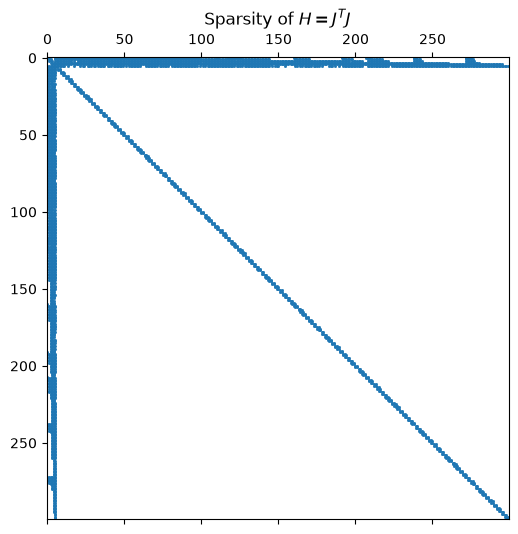

In [7]:
bins = 300
rows, cols = H.indices()
occupied = torch.zeros(bins, bins, dtype=torch.bool)
occupied[rows * bins // H.shape[0], cols * bins // H.shape[1]] = True
plt.figure(figsize=(6, 6))
plt.spy(occupied.numpy(), markersize=1)
plt.title("Sparsity of $H = J^T J$");

## Solving with conjugate gradients (torchsparsegradutils)

Given a sparse `H`, `piazzi.gauss_newton` solves the damped normal equations with `piazzi.cg_solver()` by default: Jacobi-preconditioned conjugate gradients from torchsparsegradutils, which only needs matrix-vector products with `H`. The solve is inexact, which Levenberg-Marquardt tolerates: its gain ratio checks every step.

Two settings matter for this problem:

- `damping="marquardt"` scales the damping by `diag(H)`, as Ceres does. The parameters have very different scales (focal lengths in the hundreds, distortion coefficients, poses and points), and plain `lam * I` damping makes much slower progress. It plays the role of `x_scale="jac"` in the cookbook.
- `max_step` caps every tangent coordinate per step; its default of 1 is too small for focal lengths in pixels, so we raise it.

The cookbook stops when the cost decreases by less than `ftol = 1e-4` (relative) in an iteration. `piazzi` has no `ftol`, but a callback can implement it.

In [8]:
def make_ftol_callback(ftol, history):
    def callback(info):
        history.append(info.fun.item())
        return info.accepted and (info.fun_start - info.fun).item() < ftol * info.fun_start.item()

    return callback


runs = {}


def run(name, **kwargs):
    history = [cost(x0).item()]
    t = time.perf_counter()
    res = piazzi.gauss_newton(
        system,
        x0,
        manifold=manifold,
        value_fun=cost,
        damping="marquardt",
        max_step=1e3,
        max_iter=50,
        callback=make_ftol_callback(1e-4, history),
        **kwargs,
    )
    elapsed = time.perf_counter() - t
    runs[name] = {"result": res, "history": history, "time": elapsed}
    print(f"{name}: cost {res.fun.item():.6g} after {res.n_iter} iterations, {elapsed:.1f} s ({res.message})")
    return res


res_cg = run("piazzi LM + CG", linear_solver=piazzi.cg_solver(tol=1e-3, max_iter=100))

piazzi LM + CG: cost 13425.2 after 25 iterations, 33.6 s (stopped by callback)


## Solving with the Schur complement

CG ignores the structure of $H$. Bundle-adjustment solvers instead eliminate the points: block elimination of

$$
\begin{bmatrix} U & W \\ W^\top & V \end{bmatrix}
\begin{bmatrix} \boldsymbol\delta_c \\ \boldsymbol\delta_p \end{bmatrix}
= -\begin{bmatrix} \mathbf{g}_c \\ \mathbf{g}_p \end{bmatrix}
$$

(with the damping already added to the diagonal) gives the reduced camera system

$$
(U - W V^{-1} W^\top)\,\boldsymbol\delta_c = -\mathbf{g}_c + W V^{-1} \mathbf{g}_p,
\qquad
\boldsymbol\delta_p = -V^{-1}(\mathbf{g}_p + W^\top \boldsymbol\delta_c).
$$

$V$ is block diagonal, so $V^{-1}$ is cheap, and the reduced system is only $441 \times 441$: it is solved exactly with a dense Cholesky factorisation. A `linear_solver` receives `(H, g, damping)` and returns the step, so the Schur solver reads the blocks straight from the sparse `H`.

In [9]:
def schur_solver(n_reduced, block=3):
    # Eliminates the block-diagonal trailing part of H (blocks of size `block`), then solves
    # the dense reduced system for the first `n_reduced` unknowns.

    def solve(H, g, damping):
        n = H.shape[0]
        diag = torch.arange(n)
        H = (
            H + torch.sparse_coo_tensor(torch.stack([diag, diag]), damping, H.shape, check_invariants=False)
        ).coalesce()
        (r, c), v = H.indices(), H.values()
        n_pt = (n - n_reduced) // block
        top, left = r < n_reduced, c < n_reduced
        U = torch.zeros(n_reduced, n_reduced).index_put_((r[top & left], c[top & left]), v[top & left], accumulate=True)
        m = top & ~left
        W = torch.sparse_coo_tensor(
            torch.stack([r[m], c[m] - n_reduced]), v[m], (n_reduced, n - n_reduced), check_invariants=False
        )
        m = ~top & ~left
        rr, cc = r[m] - n_reduced, c[m] - n_reduced
        assert torch.equal(rr // block, cc // block), "the trailing part of H must be block diagonal"
        V = torch.zeros(n_pt, block, block).index_put_((rr // block, rr % block, cc % block), v[m], accumulate=True)
        V_inv = torch.linalg.inv(V)
        # V^{-1} as a sparse block-diagonal matrix, to form W V^{-1} with a sparse product.
        rV, cV = block_indices((block * torch.arange(n_pt), block * torch.arange(n_pt)), block, block)
        V_inv_sparse = torch.sparse_coo_tensor(
            torch.stack([rV, cV]), V_inv.reshape(-1), (n - n_reduced,) * 2, check_invariants=False
        )
        with warnings.catch_warnings():  # sparse @ sparse goes through CSR, which torch flags as beta
            warnings.filterwarnings("ignore", "Sparse CSR tensor support is in beta", UserWarning)
            WV_inv = torch.sparse.mm(W, V_inv_sparse)
            S = U - torch.sparse.mm(WV_inv, W.t()).to_dense()
        g_c, g_p = g[:n_reduced], g[n_reduced:]
        d_c = torch.cholesky_solve((-g_c + WV_inv @ g_p)[:, None], torch.linalg.cholesky(S))[:, 0]
        rhs_p = (g_p + W.t() @ d_c).reshape(n_pt, block, 1)
        d_p = -(V_inv @ rhs_p).reshape(-1)
        return torch.cat([d_c, d_p])

    return solve


res_schur = run("piazzi LM + Schur", linear_solver=schur_solver(n_cam_dof))

piazzi LM + Schur: cost 13351.9 after 17 iterations, 4.9 s (stopped by callback)


## SciPy reference

The cookbook's solution, for comparison: `scipy.optimize.least_squares` with the trust-region reflective method, finite-difference Jacobians on the given sparsity pattern, Jacobian scaling and `ftol=1e-4`. It works on the rotation-vector parametrisation of the BAL file.

In [10]:
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from scipy.spatial.transform import Rotation


def project_np(points, camera_params):
    p = Rotation.from_rotvec(camera_params[:, :3]).apply(points) + camera_params[:, 3:6]
    p = -p[:, :2] / p[:, 2, np.newaxis]
    f, k1, k2 = camera_params[:, 6], camera_params[:, 7], camera_params[:, 8]
    n = np.sum(p**2, axis=1)
    return p * (f * (1 + k1 * n + k2 * n**2))[:, np.newaxis]


def fun_np(params):
    cams = params[: n_cameras * 9].reshape((n_cameras, 9))
    pts = params[n_cameras * 9 :].reshape((n_points, 3))
    return (project_np(pts[point_indices], cams[camera_indices]) - points_2d).ravel()


def bundle_adjustment_sparsity():
    m, n = camera_indices.size * 2, n_cameras * 9 + n_points * 3
    A = lil_matrix((m, n), dtype=int)
    i = np.arange(camera_indices.size)
    for s in range(9):
        A[2 * i, camera_indices * 9 + s] = 1
        A[2 * i + 1, camera_indices * 9 + s] = 1
    for s in range(3):
        A[2 * i, n_cameras * 9 + point_indices * 3 + s] = 1
        A[2 * i + 1, n_cameras * 9 + point_indices * 3 + s] = 1
    return A


x0_np = np.hstack((camera_params.ravel(), points_3d.ravel()))
t = time.perf_counter()
res_scipy = least_squares(
    fun_np, x0_np, jac_sparsity=bundle_adjustment_sparsity(), x_scale="jac", ftol=1e-4, method="trf"
)
runs["scipy TRF"] = {"time": time.perf_counter() - t}
print(f"scipy TRF: cost {res_scipy.cost:.6g} after {res_scipy.nfev} evaluations, {runs['scipy TRF']['time']:.1f} s")

scipy TRF: cost 13408.9 after 15 evaluations, 9.0 s


## Comparison

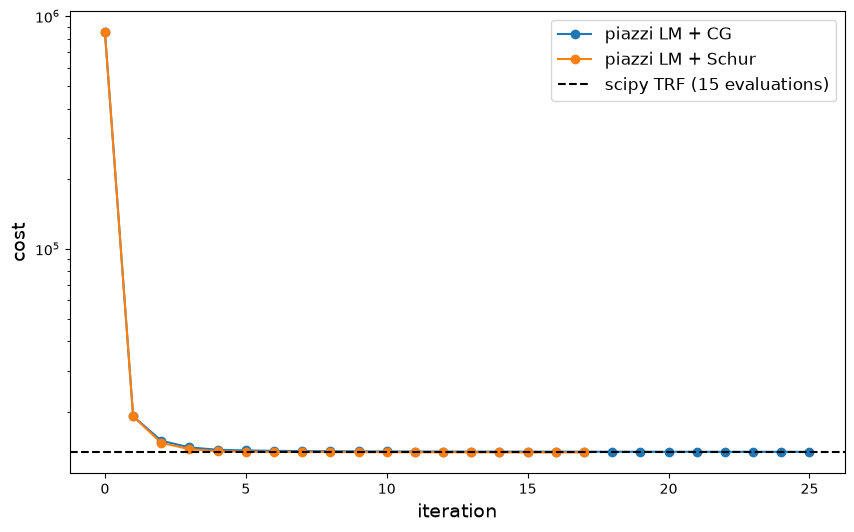

In [11]:
for name, run_ in runs.items():
    if "history" in run_:
        plt.semilogy(run_["history"], "o-", label=name)
plt.axhline(res_scipy.cost, color="k", ls="--", label=f"scipy TRF ({res_scipy.nfev} evaluations)")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.legend();

In [12]:
print(f"{'solver':20s} {'cost':>10s} {'time (s)':>9s}")
for name, run_ in runs.items():
    final = run_["result"].fun.item() if "result" in run_ else res_scipy.cost
    print(f"{name:20s} {final:10.6g} {run_['time']:9.1f}")

solver                     cost  time (s)
piazzi LM + CG          13425.2      33.6
piazzi LM + Schur       13351.9       4.9
scipy TRF               13408.9       9.0


All three runs land on solutions of essentially the same quality, about 64 times below the initial cost. The Schur solver gives the exact damped step, so its iterations follow Levenberg-Marquardt most closely and it ends slightly below SciPy's cost, in about the same number of iterations and less time. CG only solves each step approximately (100 iterations on the ill-conditioned full system), so it needs more, and slower, iterations; its advantage is that it needs nothing but `H` itself.

Every pose stayed a rigid transform: the manifold only ever composes it with rotations and translations. For use with BAL tools, the poses convert back to rotation vectors with `piazzi.so3_log`.

max |R^T R - I|: 8.881784197001252e-16
max |det R - 1|: 1.1102230246251565e-15
cost of the piazzi solution evaluated by the SciPy model: 13351.9


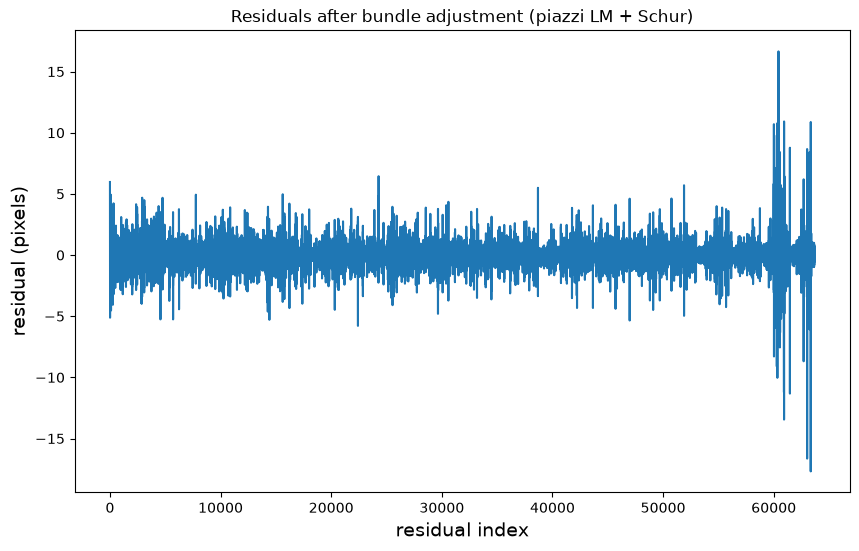

In [13]:
T, k, X = unpack(res_schur.x)
R = T[:, :3, :3]
print("max |R^T R - I|:", (R.mT @ R - torch.eye(3)).abs().max().item())
print("max |det R - 1|:", (torch.linalg.det(R) - 1).abs().max().item())

camera_params_opt = torch.cat([piazzi.so3_log(R), T[:, :3, 3], k], 1)
x_opt_np = np.hstack((camera_params_opt.numpy().ravel(), X.numpy().ravel()))
print(f"cost of the piazzi solution evaluated by the SciPy model: {0.5 * np.sum(fun_np(x_opt_np) ** 2):.6g}")

plt.plot(residuals(res_schur.x).reshape(-1))
plt.xlabel("residual index")
plt.ylabel("residual (pixels)")
plt.title("Residuals after bundle adjustment (piazzi LM + Schur)");